
⏱ Training Time: 0.42 seconds

Train Scores:
  MAE:  0.08576
  RMSE: 0.13309
  R²:   0.92958

Test Scores:
  MAE:  0.13822
  RMSE: 0.18845
  R²:   0.86812

 5-Fold Cross-Validation R² Scores:
  Fold 1: R² = 0.91036
  Fold 2: R² = 0.71861
  Fold 3: R² = 0.87539
  Fold 4: R² = 0.85669
  Fold 5: R² = 0.75282

Mean R²: 0.82277
Std Dev: 0.07394

🔍 Full Test Data (20% sample):
       Base TC    Filler TC        Vol  Composite TC
73   0.360000    10.000000  13.000000      0.600000
414  0.608445     3.477642   1.519267      0.755616
394  0.201375    29.409589  19.686976      0.606540
277  0.261151  2350.199426   3.519822      1.147362
399  0.357268    34.509569   9.090046      0.644848
..        ...          ...        ...           ...
222  0.221396   203.669502  19.940279      0.472738
237  0.317278   297.696006  24.987760      0.617363
408  0.168738    10.102983  30.443816      0.701209
25   0.150000  4000.000000   1.500000      0.270000
419  0.170486   238.334500  66.035491      0.801769


C:\Users\manas\anaconda3\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


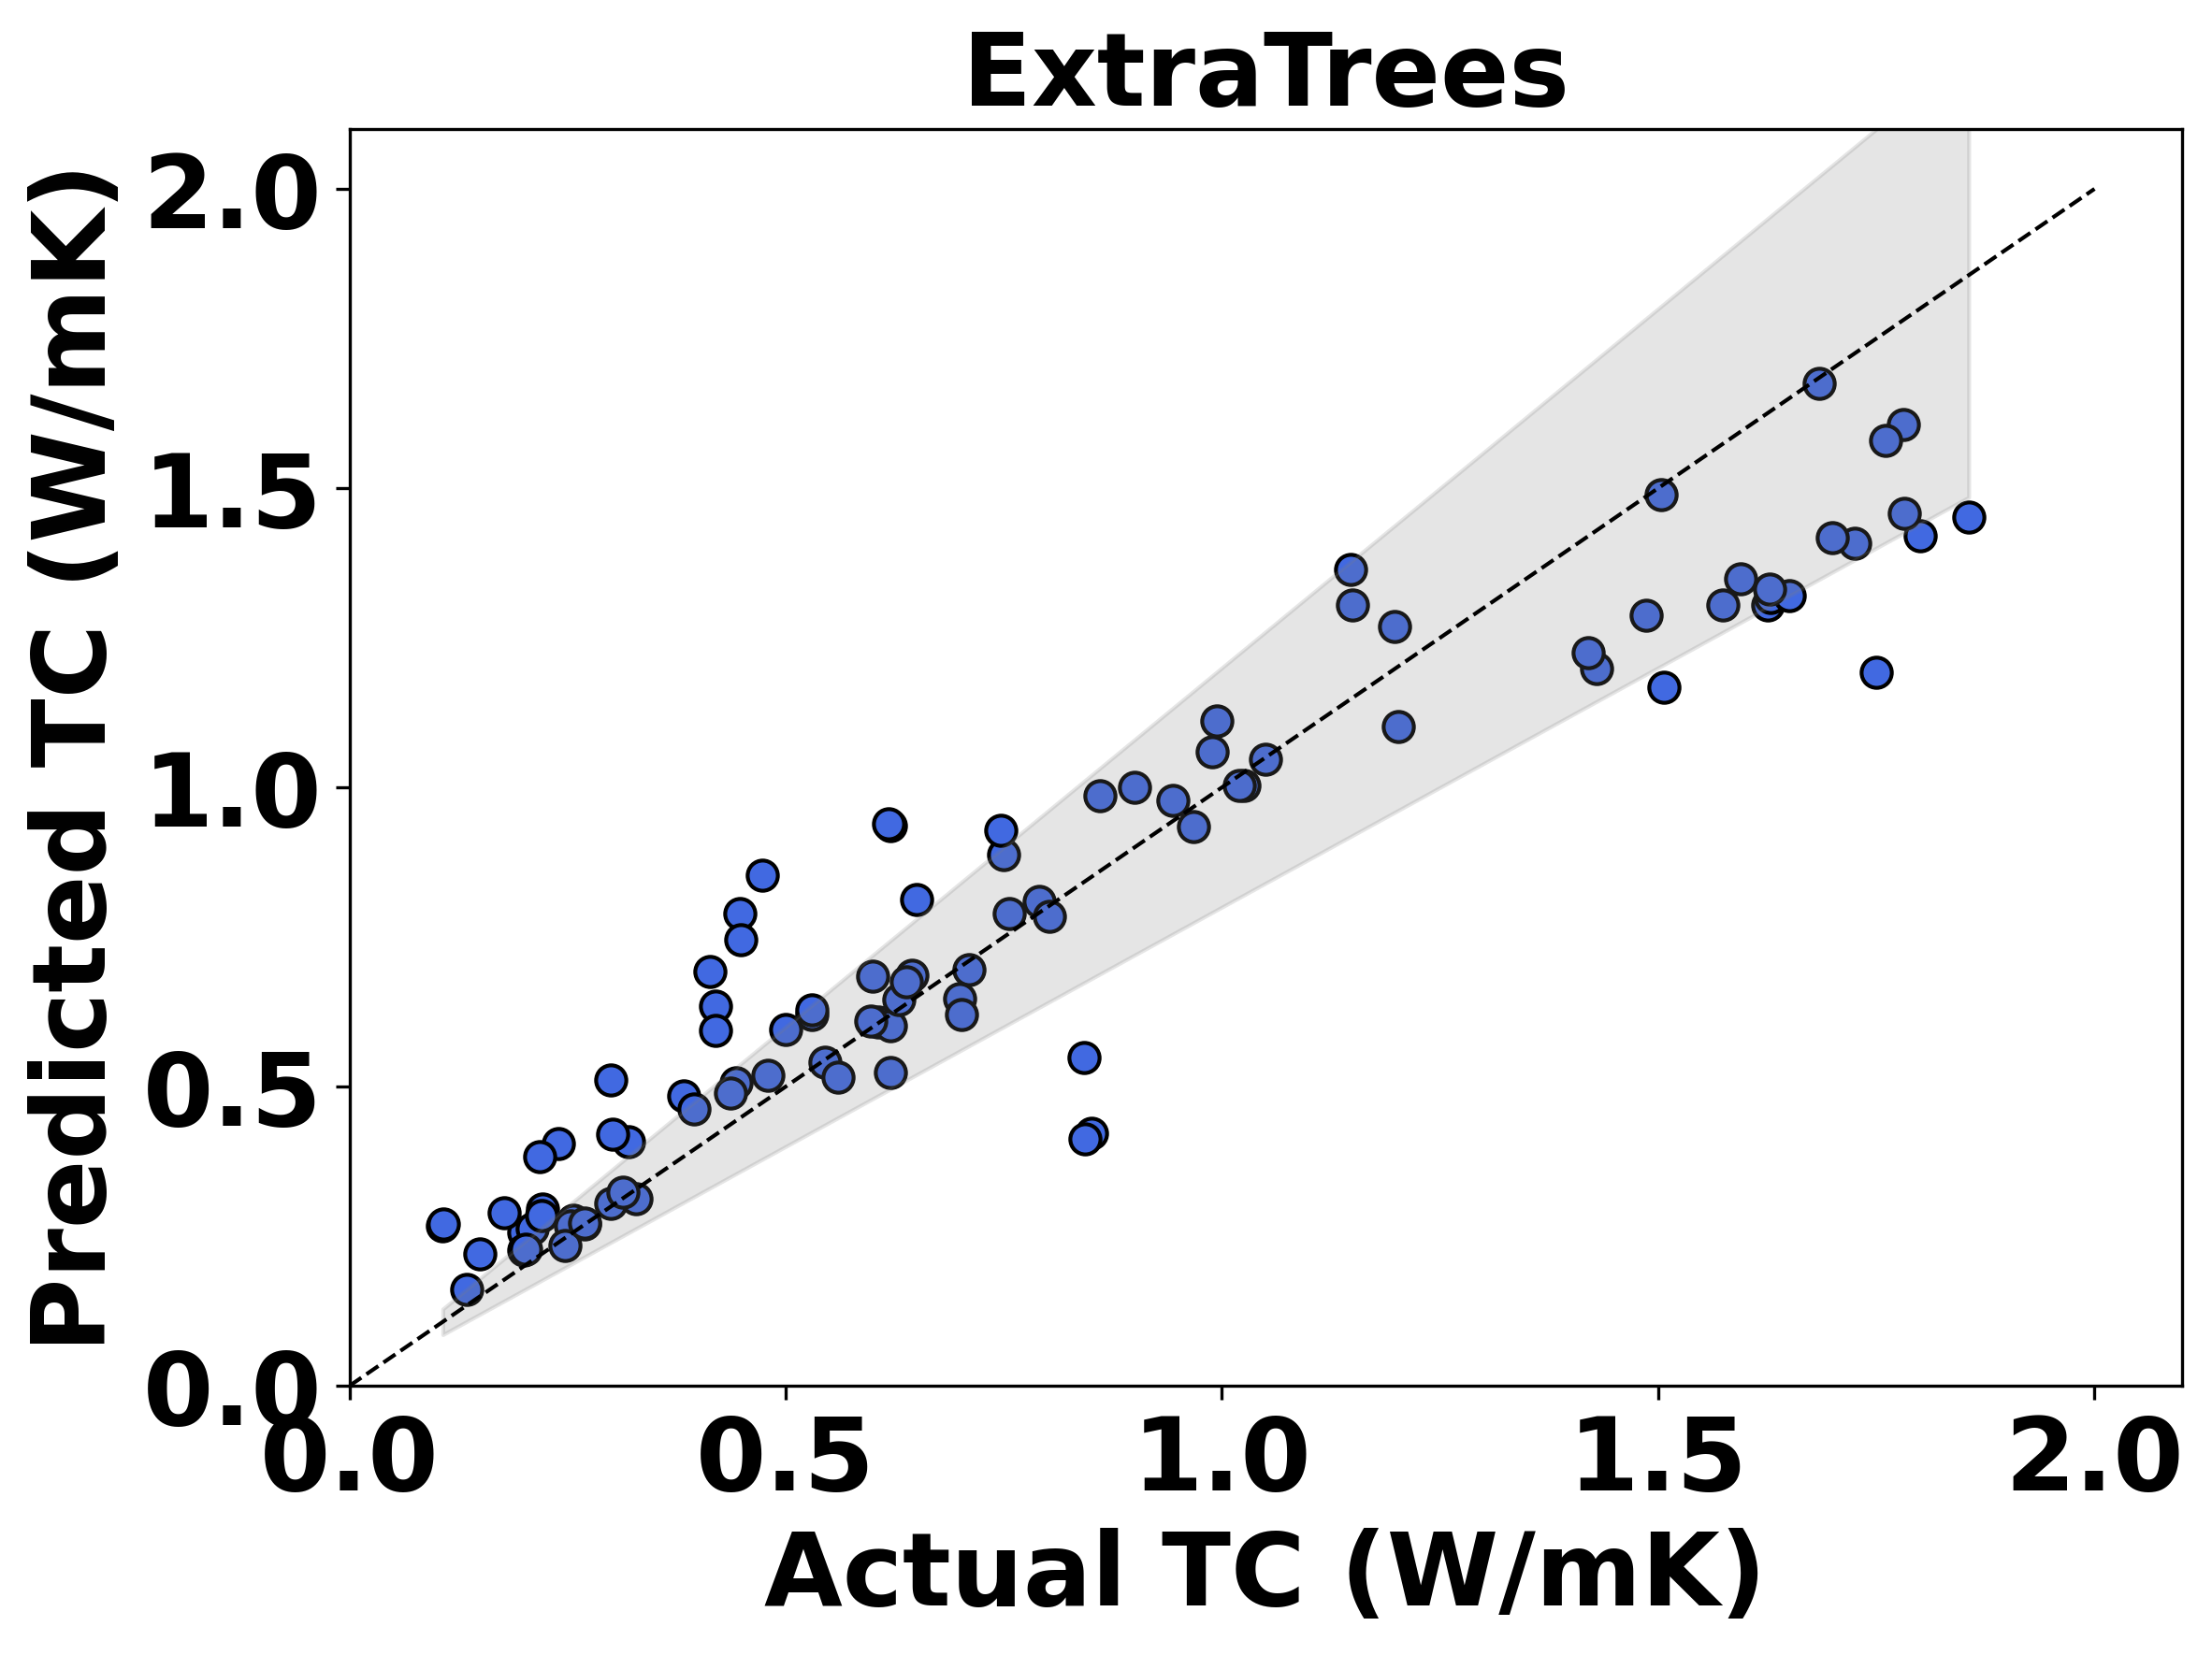

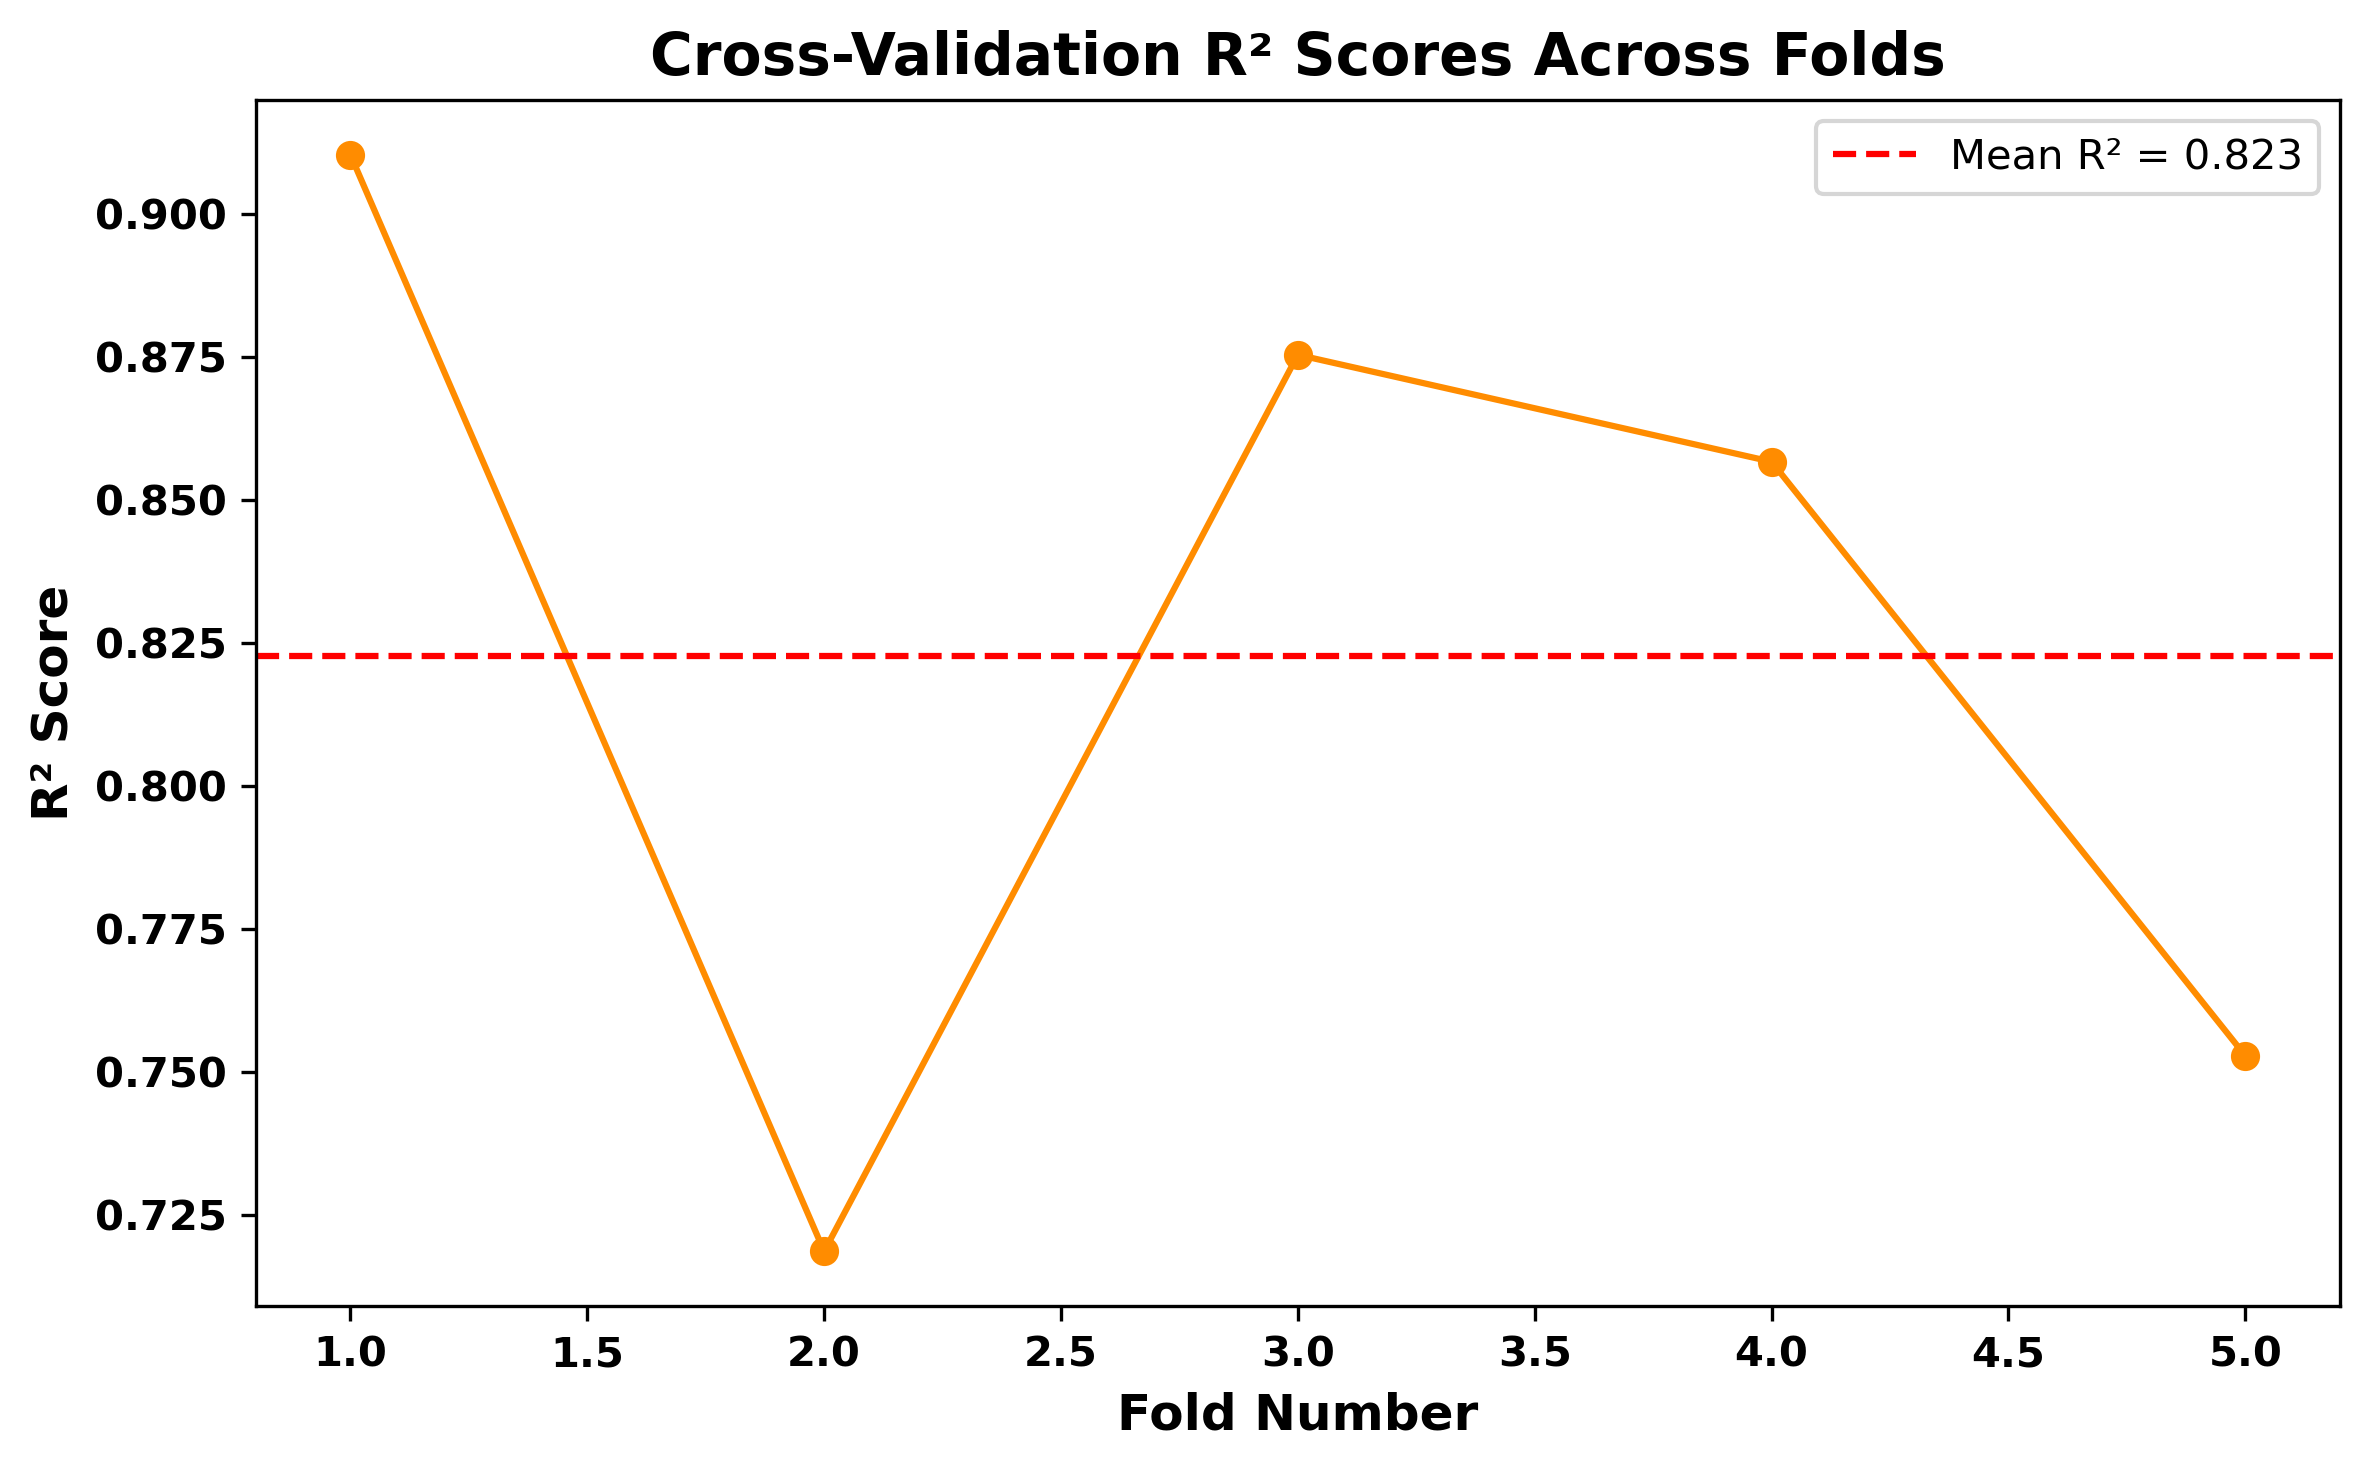

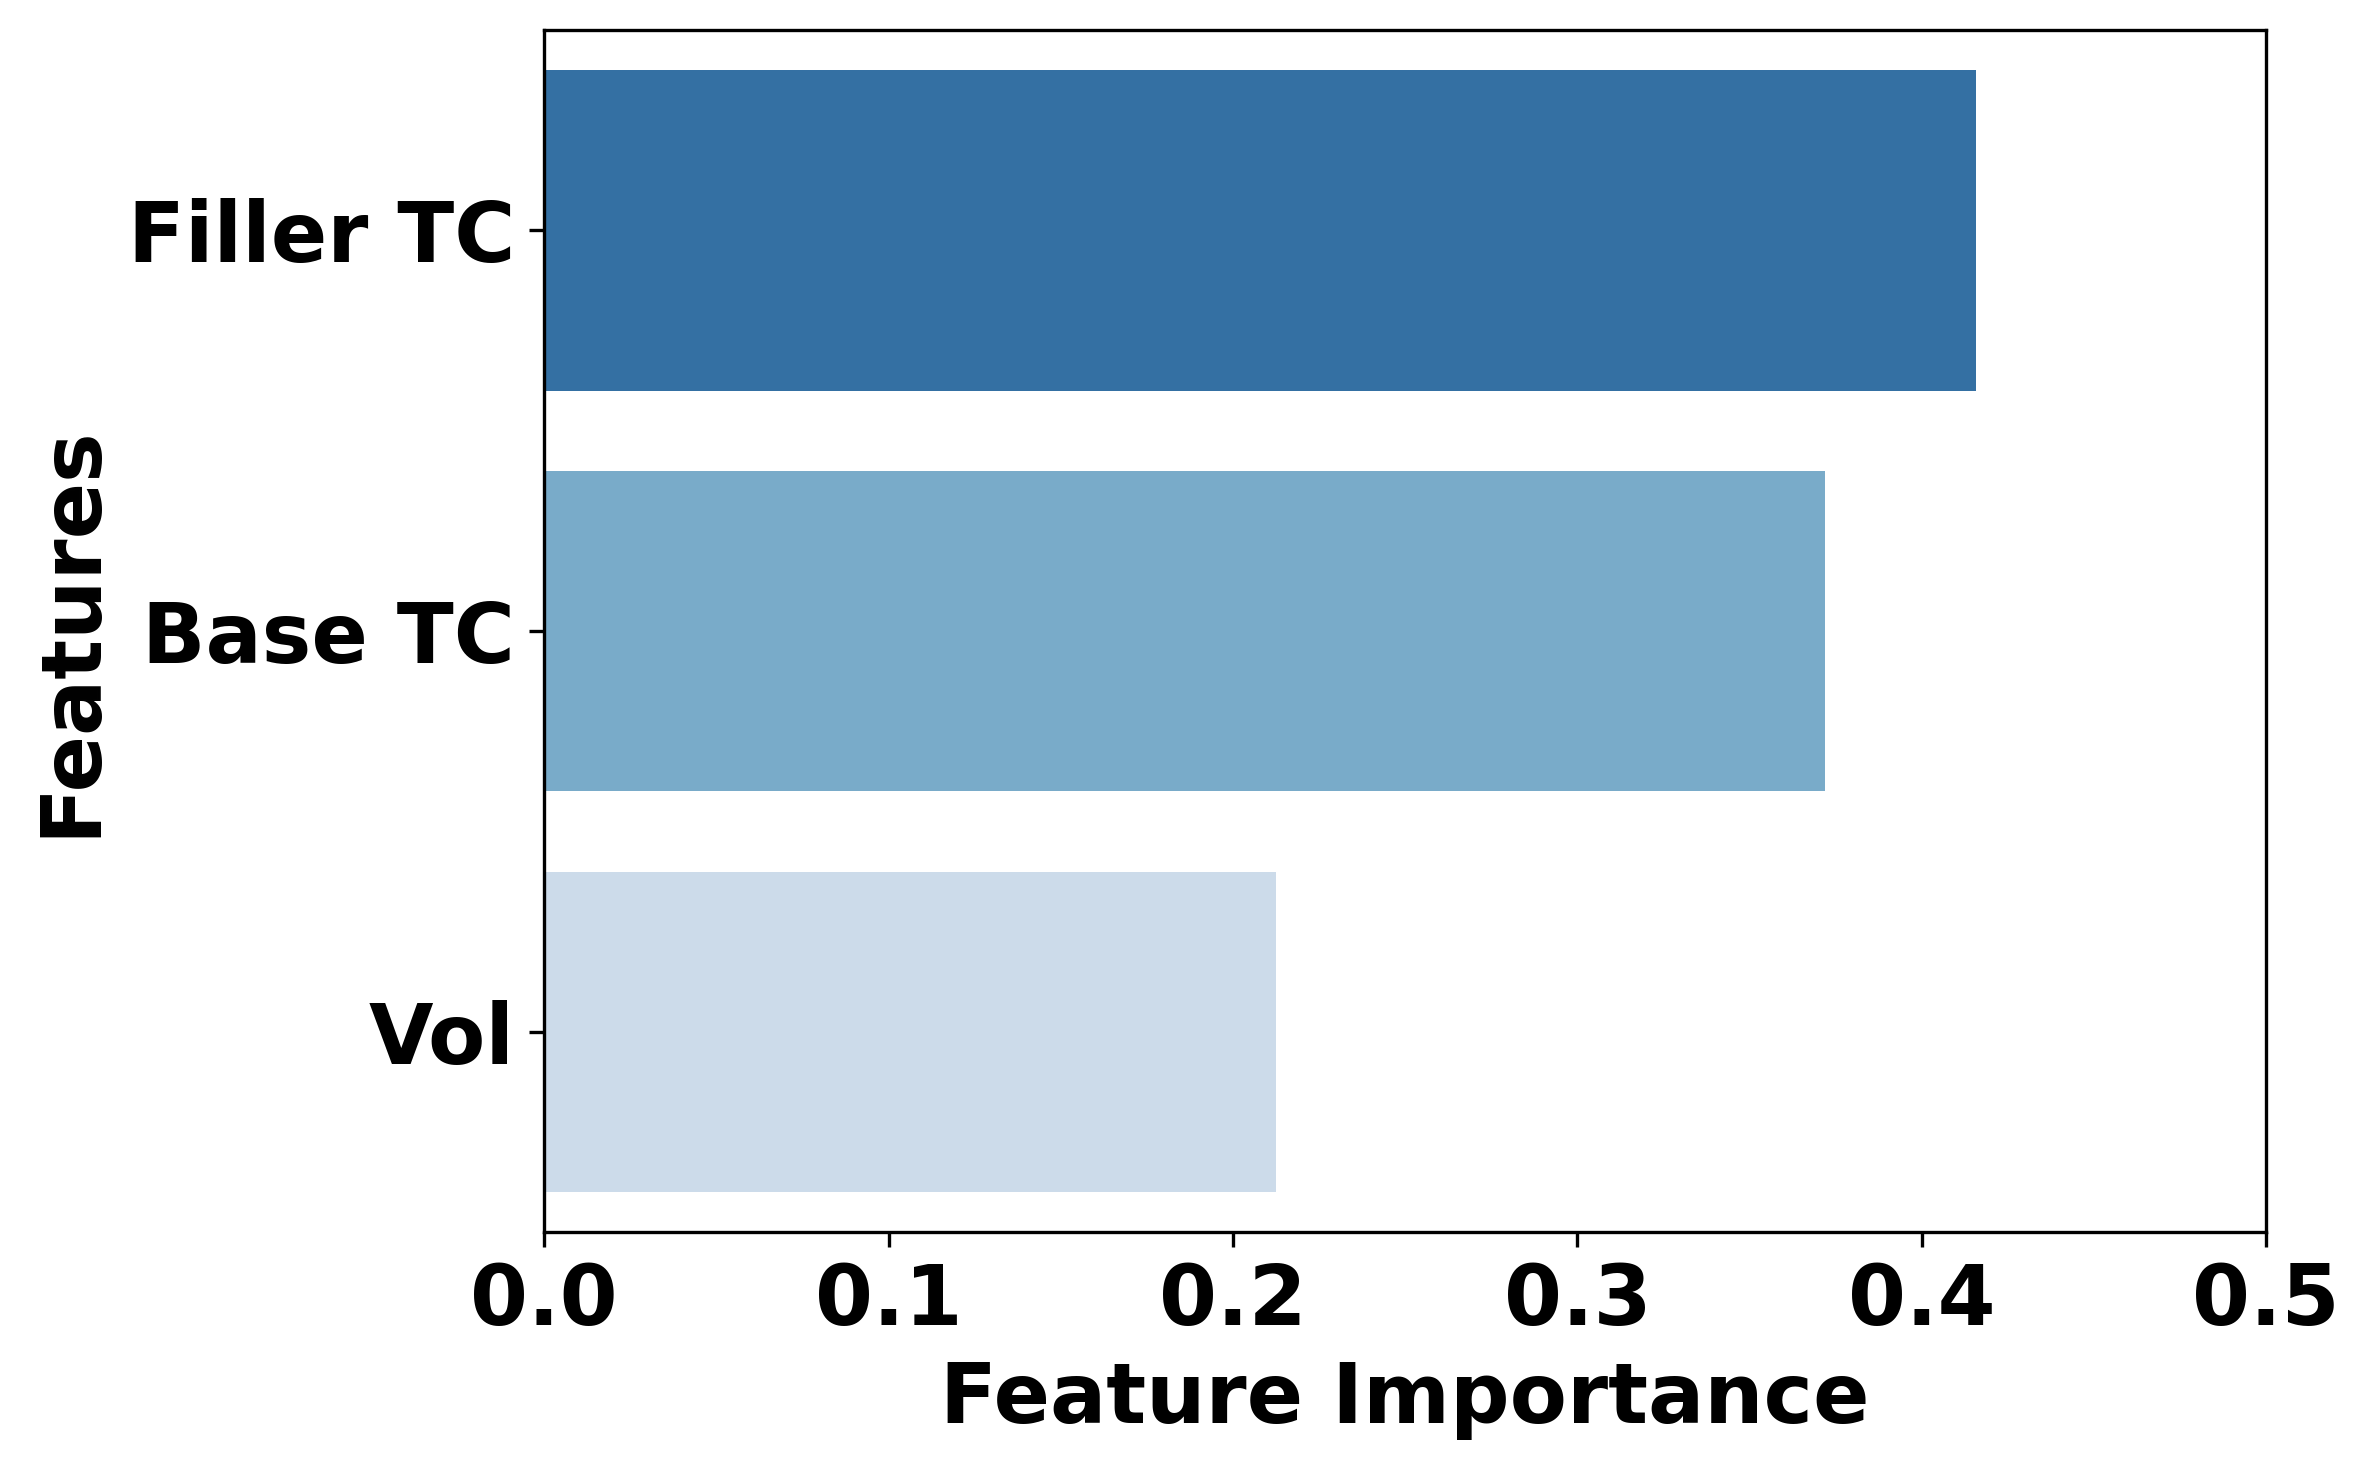

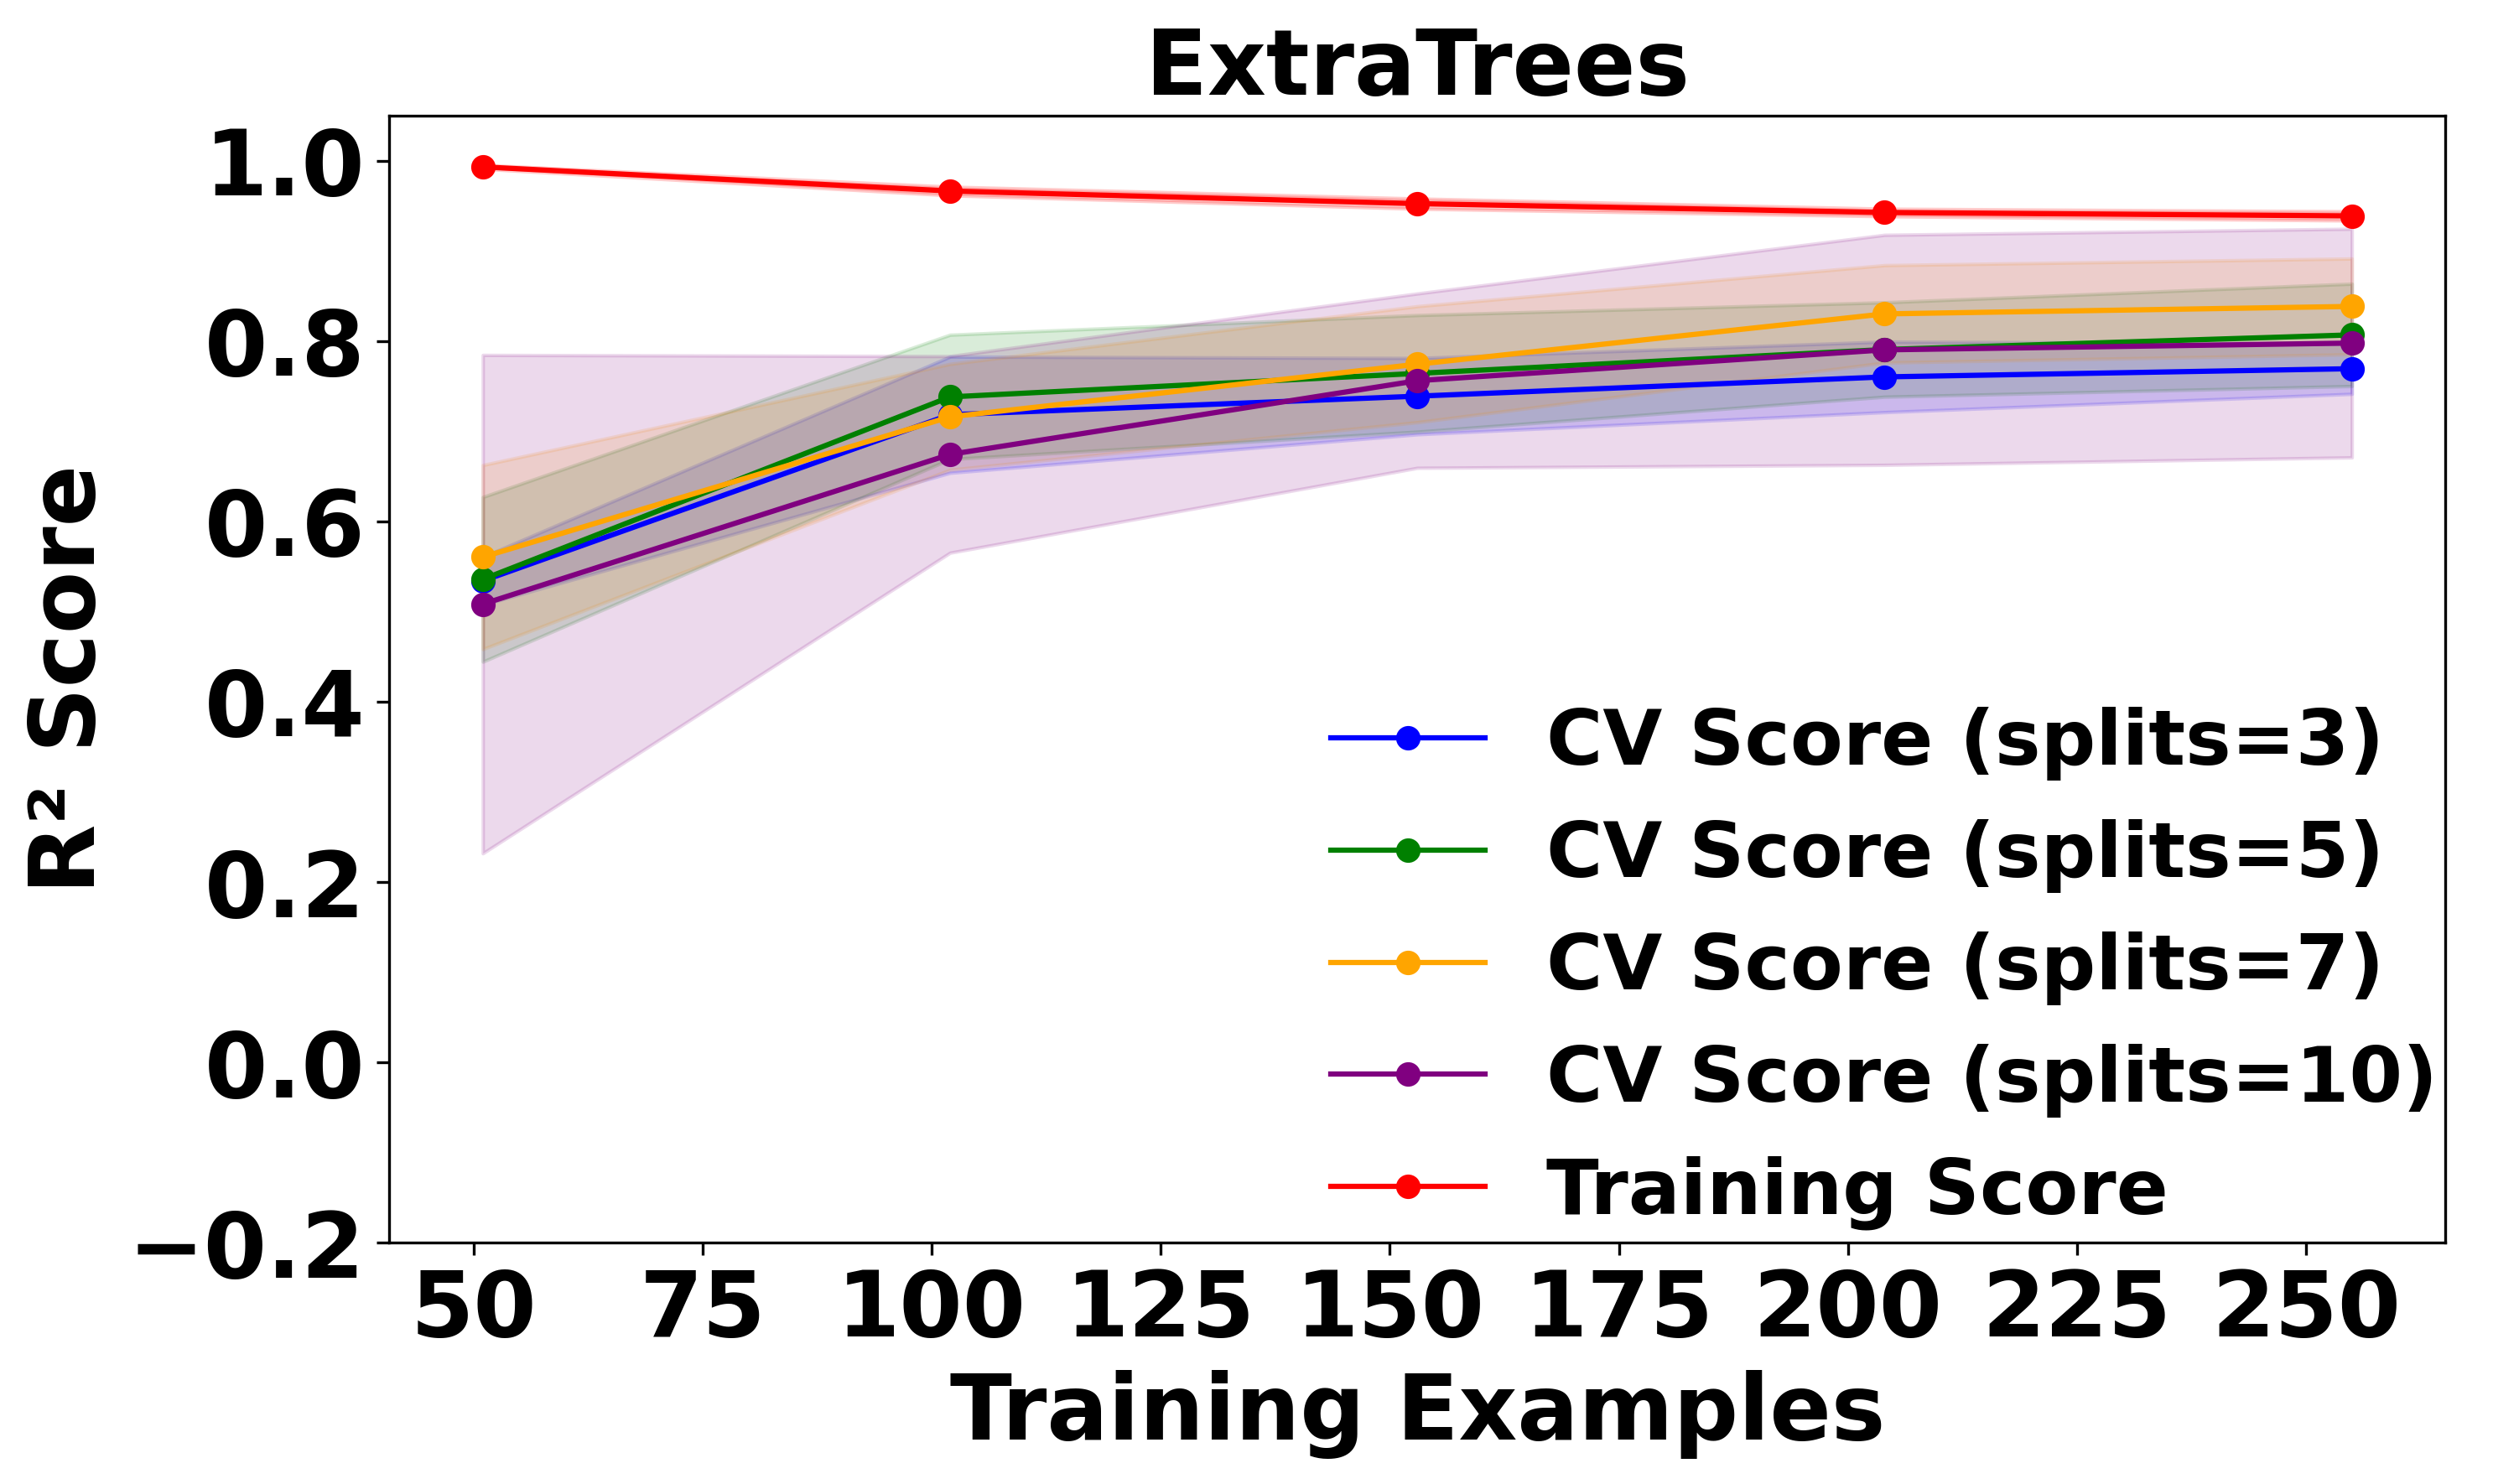

In [1]:
#Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Load dataset
file_path = r'C:\Users\manas\OneDrive\Desktop\Ml edit 22\Room\Room_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

#Features and Target
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Tuned ExtraTreesRegressor
model = ExtraTreesRegressor(
    n_estimators=150,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.8,
    max_depth=10,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

#Train Model
start = time.time()
model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

#Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

#Evaluation Function
def print_scores(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{label} Scores:")
    print(f"  MAE:  {mae:.5f}")
    print(f"  RMSE: {rmse:.5f}")
    print(f"  R²:   {r2:.5f}")

#Final Evaluation
print_scores(y_train, y_train_pred, "Train")
print_scores(y_test, y_test_pred, "Test")

#5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
print("\n 5-Fold Cross-Validation R² Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: R² = {score:.5f}")
print(f"\nMean R²: {cv_scores.mean():.5f}")
print(f"Std Dev: {cv_scores.std():.5f}")

#Full Test Data Output
test_combined = X_test.copy()
test_combined['Composite TC'] = y_test
print("\n🔍 Full Test Data (20% sample):\n", test_combined)

#Manual prediction
manual_input = [[1.05, 16, 15]]
predicted_tc = model.predict(manual_input)
print(f"\n Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

#Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.80
upper = y_true * 1.20
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(
    np.sort(y_true),
    lower[sorted_idx],
    upper[sorted_idx],
    color='gray',
    alpha=0.2
)
plt.plot([0, 2.0], [0, 2.0], 'k--', lw=1)
plt.xlim(0, 2.10)
plt.ylim(0, 2.10)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('ExtraTrees', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

#Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

#Feature Importance
importances = model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5), dpi=300)
sns.barplot(x=importances[indices], y=feature_names[indices], palette="Blues_r")
plt.xlabel('Feature Importance', fontsize=20, fontweight='bold')
plt.ylabel('Features', fontsize=20, fontweight='bold')
# Set x-tick step size to 0.10
max_val = importances[indices].max()
plt.xticks(np.arange(0, max_val + 0.10, 0.10), fontsize=20, fontweight='bold')
plt.xticks(fontsize=20, fontweight='bold')
plt.yticks(fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()


#Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
# train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)
step = min_allowed_size // 5
train_sizes_fixed = np.arange(step, min_allowed_size + 1, step)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', color=color, label=f'CV Score (splits={split})')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('ExtraTrees', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()


In [13]:
#Manual prediction
manual_input = [[1.05, 16.2, 10]]
predicted_tc = model.predict(manual_input)
print(f"\n Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")


 Predicted Composite TC for input [1.05, 16.2, 10]: 1.4123


C:\Users\manas\anaconda3\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


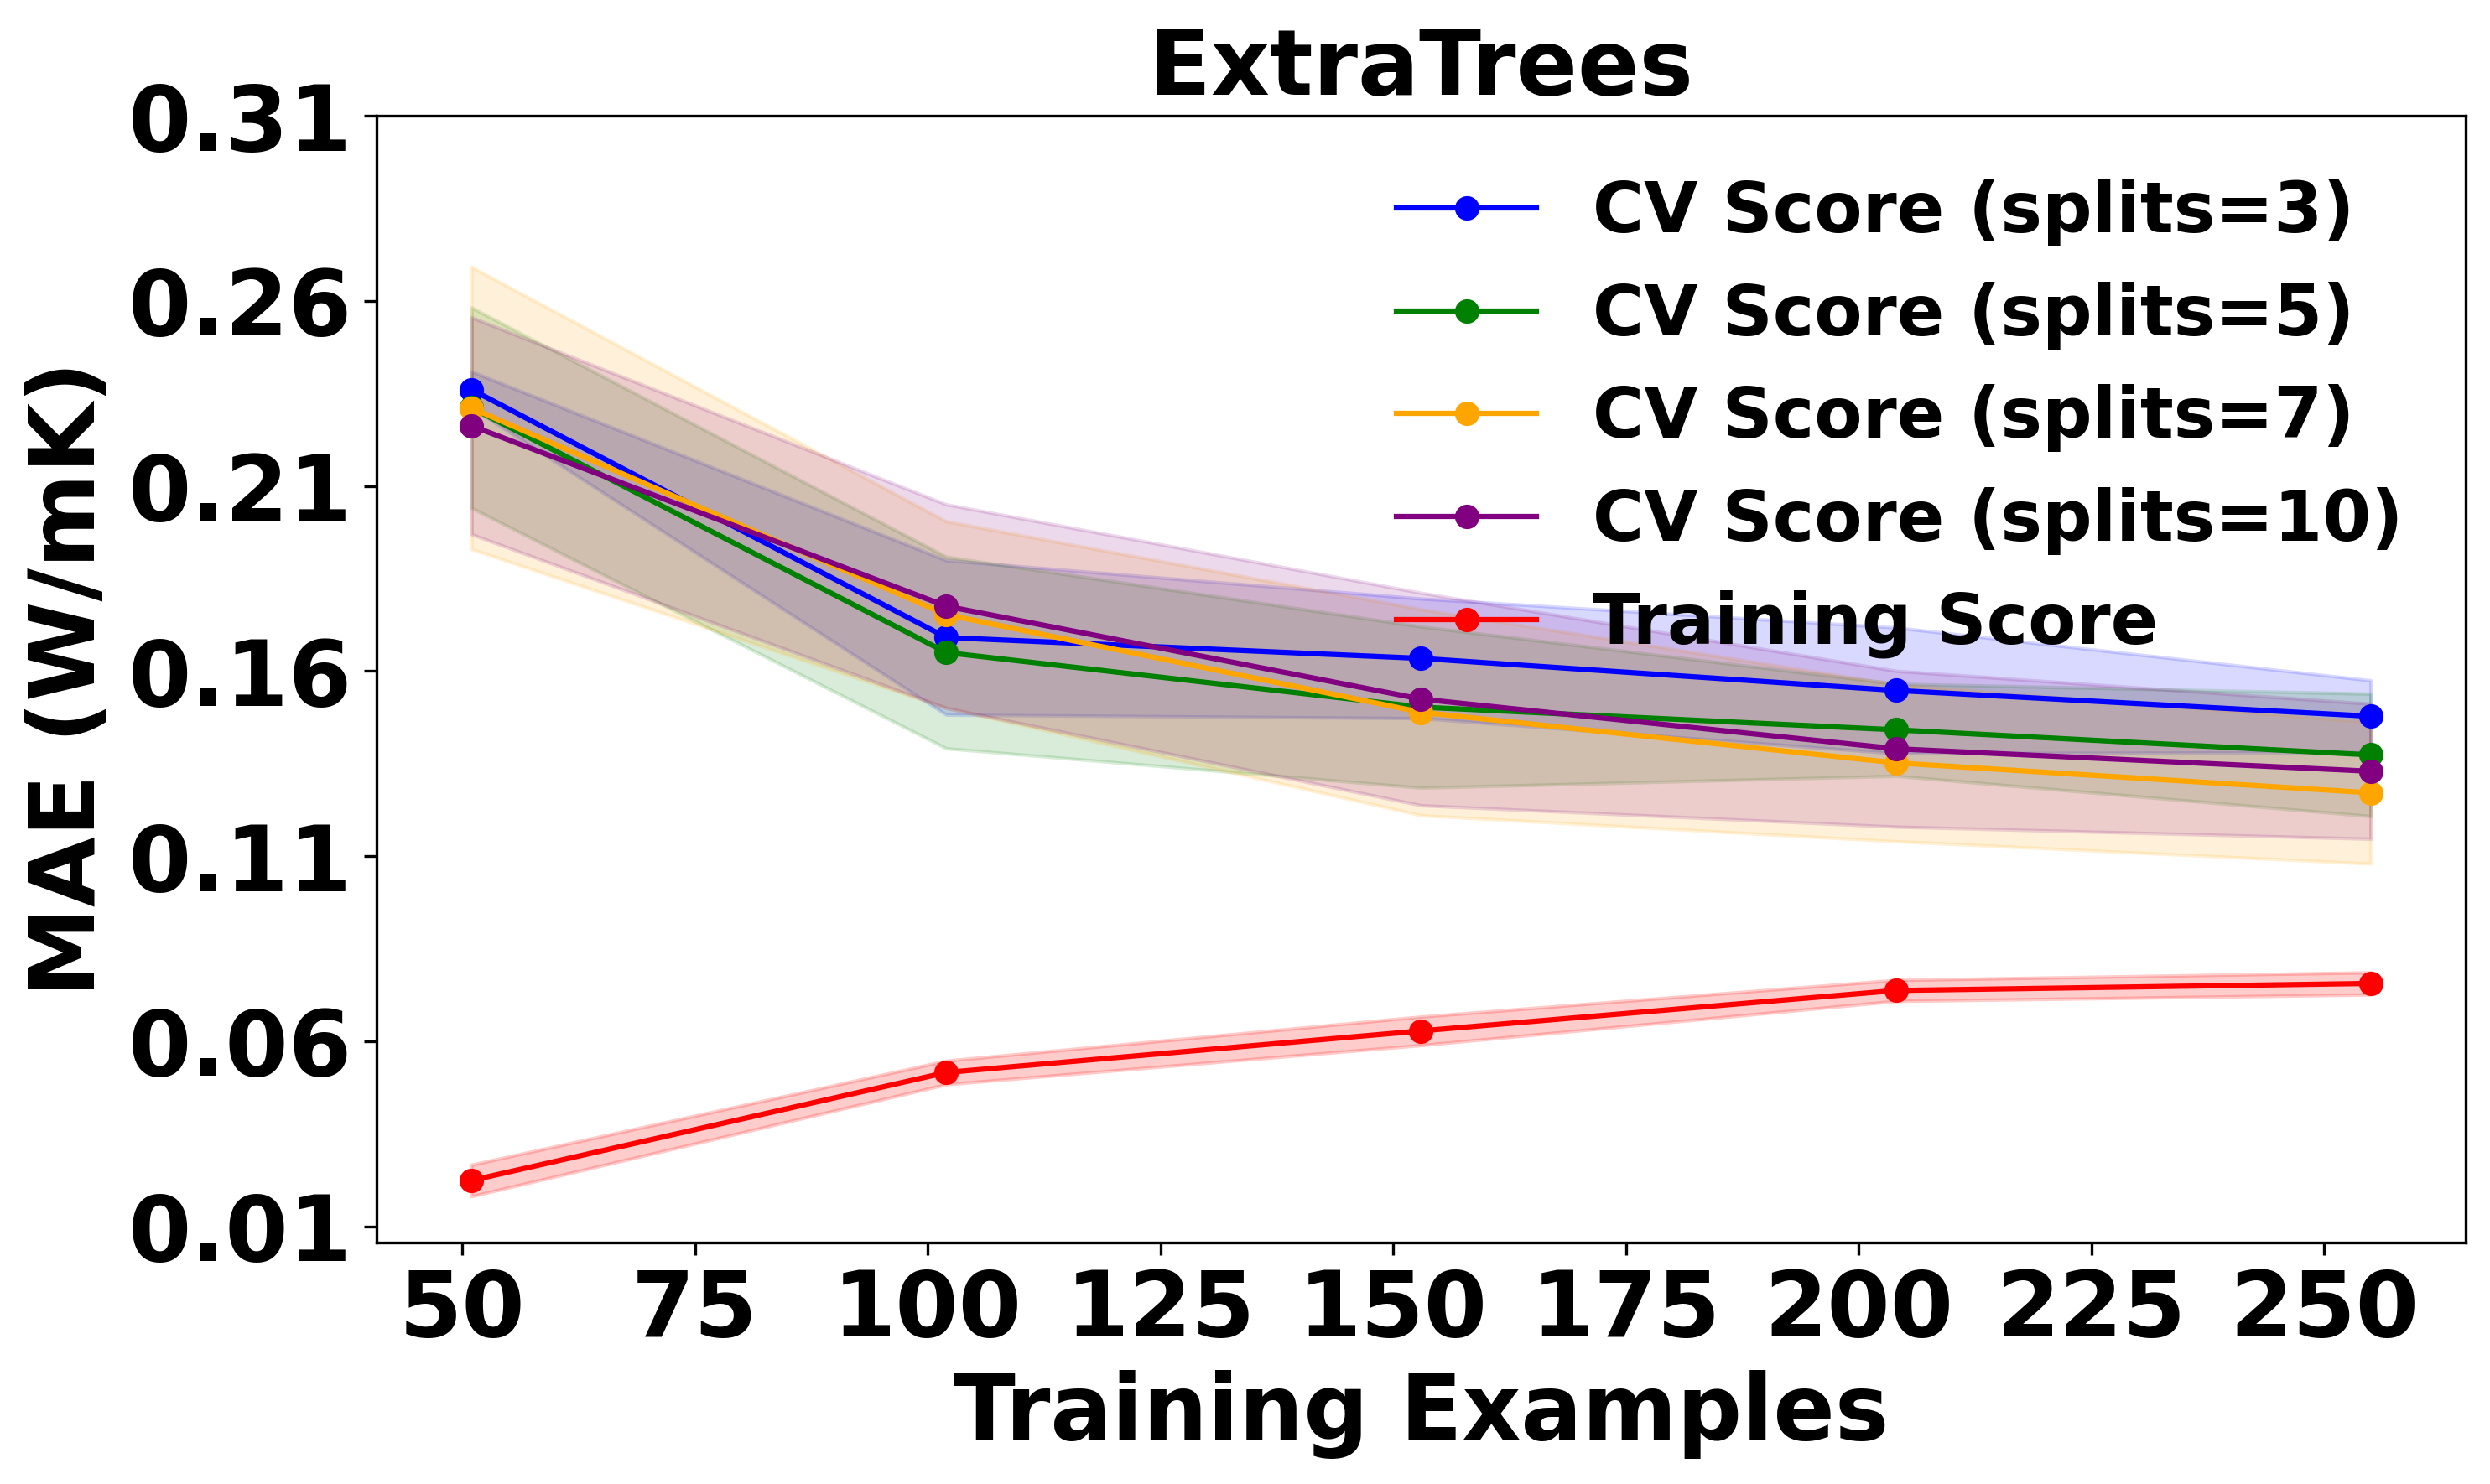

In [11]:
# Learning Curve (MAE)
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
# train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)
step = min_allowed_size // 5
train_sizes_fixed = np.arange(step, min_allowed_size + 1, step)


plt.figure(figsize=(10, 6), dpi=300)

for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    val_mean = -np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    plt.plot(train_sizes, val_mean, marker='o',
             label=f'CV Score (splits={split})',
             color=color)

    plt.fill_between(train_sizes,
                     val_mean - val_std,
                     val_mean + val_std,
                     color=color,
                     alpha=0.15)

train_mean = -np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)

plt.plot(train_sizes, train_mean, marker='o',
         color='red', label='Training Score')

plt.fill_between(train_sizes,
                 train_mean - train_std,
                 train_mean + train_std,
                 color='red', alpha=0.2)

plt.title('ExtraTrees', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('MAE (W/mK)', fontsize=26, fontweight='bold')

# 🔹 Set Y-axis step to 0.05
y_min, y_max = plt.ylim()
plt.yticks(np.arange(round(y_min, 2), round(y_max, 2) + 0.05, 0.05),
           fontsize=26, fontweight='bold')

plt.xticks(fontsize=26, fontweight='bold')

# 🔹 Legend at top right
plt.legend(loc='upper right',
           prop={'weight': 'bold', 'size': 20},
           frameon=False)

plt.grid(False)
plt.tight_layout()
plt.show()
